# Fourteen predictors through ten folds: what each one scores and where each one refuses

**Question:** Why does each predictor refuse where it does, and how do the predictors rank on the rows they all answer?

**Level 2: The method in practice** · Needs: 05-learned-arms/01-fitting-a-learned-arm-on-nine-sites · Reading time: about 35 minutes

## Objectives

The product's benchmark runs fourteen predictors: two controls, the classical family, the statistical ones and the learned tier. Each answers a blast with a number or with a stated refusal, and a refusal is a result, never averaged away. This notebook runs the whole ladder through the ten leave-one-campaign-out folds, classifies every refusal by its cause and asks how the predictors rank when they are compared on the same rows.

By the end you will have:

- run all fourteen predictors fold by fold, one tier at a time, and scored each on the rows it answered;
- drawn the matrix of refusals by predictor and campaign and named the three causes of a refusal;
- seen the values a model returned when the engine refused them, against the plausible range of a fragment size;
- re-scored every size predictor on the 79 rows they all answered and read what that does to the ranking.

## Setup

Install the packages with the exact pins of `notebooks/requirements.txt`. The engine is `blastfrag`, published on PyPI; the other packages are its numerical base and the plotting library.

```bash
pip install blastfrag==0.4.0 numpy==2.5.4 matplotlib==3.11.2
```

The setup cell imports the packages, prints their versions, loads the corpus and defines `Table`, which shows rows as a Markdown table in Jupyter and as aligned text elsewhere. It also imports `json` for the one reproduction check at the end.

In [1]:
# Imports, package versions and the corpus loader
from importlib.metadata import version
from pathlib import Path
import json

import blastfrag as bf
import matplotlib.pyplot as plt
import numpy as np

for name in ("blastfrag", "numpy", "matplotlib"):
    print(f"{name}=={version(name)}")

DERIVED = Path("../../../data/derived")
train = bf.load_training_corpus()
print(len(train), "blasts from", len({b.site for b in train}), "campaigns")

class Table:
    """Rows under a header, shown as a Markdown table"""

    def __init__(self, header, rows):
        self.header = list(header)
        self.rows = [[str(cell) for cell in row] for row in rows]

    def _repr_markdown_(self):
        lines = ["| " + " | ".join(self.header) + " |", "|" + "---|" * len(self.header)]
        lines += ["| " + " | ".join(row) + " |" for row in self.rows]
        return "\n".join(lines)

    __repr__ = _repr_markdown_

blastfrag==0.4.0
numpy==2.5.4
matplotlib==3.11.2
97 blasts from 10 campaigns


## Data

| Source | Owner and URL | Licence class | File the notebook reads |
|---|---|---|---|
| The 97 blasts | Hudaverdi, Kulatilake and Kuzu 2010, https://doi.org/10.1002/nag.957 | numeric facts reused with citation; the article never ships | the corpus inside the `blastfrag` wheel |
| The fourteen predictors as published | Kulatilake, Hudaverdi and Wu 2012, https://doi.org/10.1007/s10706-012-9496-3; Sui et al. 2025, https://doi.org/10.3390/app15031254; and the papers cited in topic 02 | the methods are cited, the engine implements them | `bf.default_arms()` |
| The pooled scores the offline bake wrote, for the one reproduction check | this repository (MIT), written by the offline bake | the product's own licence | `data/derived/benchmark.json`, field `protocols` |

## Method

A predictor refuses for one of three causes, and the engine declares each rather than hiding it:

1. **A needed input cannot be known (A).** The classical family needs a rock volume and a charge mass, which come from the hole diameter. A campaign that publishes none cannot supply them, and the engine will not invent a burden.
2. **It is not a size predictor (B).** The group discriminant assigns a rock-stiffness group; by design it never returns a size.
3. **The output leaves the physical range (C).** A mean fragment size lies between a millimetre and a few metres. A model that returns a number outside `bf.models.PLAUSIBLE_X50_M` has left its domain, and the engine refuses the number instead of scoring it. Without that guard, a refitted power law that extrapolates would be scored on its absurd numbers and would swamp the pooled figure of the predictor.

Because the predictors answer different numbers of rows, a score pooled over each one's own rows compares different denominators. The fair comparison is on the rows every size-predicting predictor answered, the common rows, reported beside the predictor's own score and never as the verdict, since the rows are chosen by the predictors' own refusals. The score throughout is `r2_identity`, the variance explained about the 1:1 line, with the campaign held out in each fold.

### Step 1: the ten folds and the four tiers

`leave_one_site_out` yields ten splits, one per campaign. Every predictor is built fresh in every fold by its factory in `bf.default_arms()`, because reusing one instance would let the fit of one fold leak into the next. The cell lists the folds and the four tiers of the ladder.

In [2]:
# The ten leave-one-site-out folds and the tier of each of the fourteen predictors
folds = list(bf.leave_one_site_out(train))
tested = [blast for fold in folds for blast in fold.test]
factories = bf.default_arms()
tiers = {name: make().tier for name, make in factories.items()}
print(len(folds), "folds,", len(tested), "out-of-fold blasts, each predictor built fresh in every fold")
for tier in ("control", "classical", "statistical", "learned"):
    print(f"{tier:<12}", [name for name, t in tiers.items() if t == tier])

10 folds, 97 out-of-fold blasts, each predictor built fresh in every fold
control      ['null', 'oracle']
classical    ['kuznetsov', 'kuznetsov-transfer', 'kuznetsov-capped']
statistical  ['group-discriminant', 'published-regression', 'refitted-regression']
learned      ['published-neural-net', 'svr-rbf', 'svr-poly', 'random-forest', 'xgboost', 'stacking']


### Step 2: run the ladder, tier by tier

The first tier holds the controls (the null, which predicts the training mean, and the oracle, which is handed the true size and bounds the score from above) and the three variants of the classical equation. The cell runs each through the ten folds, pools the out-of-fold answers and scores them, and prints what the classical predictor was fitted on.

In [3]:
# Controls and the classical family through the ten folds
predictions = {}
for name in [n for n, tier in tiers.items() if tier in ("control", "classical")]:
    predictions[name] = [p for fold in folds for p in factories[name]().fit(fold.train).predict(fold.test)]
scores = {name: bf.score(tested, predictions[name], method=name) for name in predictions}
print("kuznetsov, fitted on:", factories["kuznetsov"]().fitted_on)
rows = [(n, s.n_scored, s.n_abstained, f"{s.r2_identity:.3f}", f"{s.rmse_m:.3f}") for n, s in scores.items()]
Table(["predictor", "answered", "refused", "r2", "RMSE (m)"], rows)

kuznetsov, fitted on: nothing in any split: the per-site rock factor is back-solved from the 2012 paper's published Kuz-Ram predictions for that site's own hold-out blasts


| predictor | answered | refused | r2 | RMSE (m) |
|---|---|---|---|---|
| null | 97 | 0 | -0.216 | 0.207 |
| oracle | 97 | 0 | 1.000 | 0.000 |
| kuznetsov | 91 | 6 | 0.311 | 0.153 |
| kuznetsov-transfer | 91 | 6 | 0.298 | 0.154 |
| kuznetsov-capped | 91 | 6 | 0.352 | 0.148 |

The statistical tier holds the group discriminant, the published regression of Hudaverdi et al. 2010 and a refit of that power law on each fold's training rows. The cell runs the three and prints what the published regression was fitted on, because that decides how its score is to be read.

In [4]:
# The statistical tier through the same folds; the discriminant never answers a size
for name in [n for n, tier in tiers.items() if tier == "statistical"]:
    predictions[name] = [p for fold in folds for p in factories[name]().fit(fold.train).predict(fold.test)]
    scores[name] = bf.score(tested, predictions[name], method=name)
print("published-regression, fitted on:", factories["published-regression"]().fitted_on)
rows = [(n, s.n_scored, s.n_abstained, f"{s.r2_identity:.3f}" if s.n_scored else "-",
    f"{s.rmse_m:.3f}" if s.n_scored else "-")
        for n, s in scores.items() if tiers[n] == "statistical"]
Table(["predictor", "answered", "refused", "r2", "RMSE (m)"], rows)

published-regression, fitted on: all 97 blasts of the training corpus, by Hudaverdi et al. 2010


| predictor | answered | refused | r2 | RMSE (m) |
|---|---|---|---|---|
| group-discriminant | 0 | 97 | - | - |
| published-regression | 97 | 0 | 0.802 | 0.083 |
| refitted-regression | 93 | 4 | -4.075 | 0.431 |

The learned tier holds the six predictors of notebook 01. Each is refitted in each of the ten folds, so this is the slowest cell of the notebook.

In [5]:
# The learned tier: six predictors refitted in each of the ten folds, about fifteen seconds
for name in [n for n, tier in tiers.items() if tier == "learned"]:
    predictions[name] = [p for fold in folds for p in factories[name]().fit(fold.train).predict(fold.test)]
    scores[name] = bf.score(tested, predictions[name], method=name)
rows = [(n, s.n_scored, s.n_abstained, f"{s.r2_identity:.3f}", f"{s.rmse_m:.3f}") for n,
    s in scores.items() if tiers[n] == "learned"]
Table(["predictor", "answered", "refused", "r2", "RMSE (m)"], rows)

| predictor | answered | refused | r2 | RMSE (m) |
|---|---|---|---|---|
| published-neural-net | 97 | 0 | -0.626 | 0.239 |
| svr-rbf | 96 | 1 | -0.387 | 0.221 |
| svr-poly | 86 | 11 | -4.546 | 0.432 |
| random-forest | 97 | 0 | -0.231 | 0.208 |
| xgboost | 97 | 0 | -0.034 | 0.191 |
| stacking | 97 | 0 | -0.035 | 0.191 |

**What the three tables show.** The oracle scores 1.000 with no error, as a control should, and the null scores -0.216 with an RMSE of 0.207 m: pooled over ten campaigns, even the training mean misses by a fifth of a metre. The classical equation and its two variants score 0.311, 0.298 and 0.352 on the 91 blasts they answer. The published regression scores 0.802, but the line printed above says it was fitted on all 97 blasts of the corpus, so that number is a fit to these rows and not a prediction for a campaign it did not see. The same applies, in a weaker form, to the classical predictor, whose per-site rock factor is back-solved from the source's published predictions for that site. Among the learned predictors only boosting (-0.034) and stacking (-0.035) come close to zero; the network scores -0.626, the forest -0.231, the radial support vector regressor -0.387 and the polynomial one -4.546. **What the tables do not show:** how many rows each predictor left unanswered, which is the next step.

### Step 3: every refusal, with its cause

Cause A depends on what each campaign publishes about its geometry. The first cell asks the engine, with `has_absolute_geometry`, which campaigns fix an absolute scale, and lists the hole diameter each one publishes. The second cell counts every refusal by predictor and campaign and names its kind from the engine's own reason text. The figure draws the result as a matrix.

In [6]:
# What each campaign publishes about its geometry, and so which campaigns the classical family can run on
sites = sorted({blast.site for blast in train})
rows = []
for site in sites:
    first = next(blast for blast in train if blast.site == site)
    diameter = bf.SITE_GEOMETRY[site].hole_diameter_mm
    rows.append((site, "yes" if bf.has_absolute_geometry(first) else "no", diameter if diameter else "-"))
Table(["campaign", "scale fixed", "hole diameter (mm)"], rows)

| campaign | scale fixed | hole diameter (mm) |
|---|---|---|
| Akdaglar | yes | 89.0 |
| Dongri-Buzurg | yes | 100.0 |
| Enusa | yes | 165.0 |
| Miami | no | - |
| Mrica | yes | 76.0 |
| Murgul | yes | 165.0 |
| Ozmert | yes | 89.0 |
| Reocin | yes | 229.0 |
| Reocin-UG | yes | 91.2 |
| Soma | yes | 210.0 |

The next cell classifies every refusal of the ladder. It counts, for each predictor and campaign, the blasts that came back without a size, and it names the kind of refusal (A, B or C of the Method section) by looking for a phrase in the reason text that the engine attached. The result is the matrix the figure draws.

In [7]:
# Count each predictor's refusals by campaign and name their kind from the engine's own reason text
KINDS = {"publishes no hole diameter": "A", "assigns a rock-stiffness group": "B", "outside the plausible": "C"}
refusals = {name: {} for name in predictions}
kind_of = {}
for name, preds in predictions.items():
    for blast, p in zip(tested, preds):
        if p.abstained:
            refusals[name][blast.site] = refusals[name].get(blast.site, 0) + 1
            kind_of[name] = next(kind for text, kind in KINDS.items() if text in p.abstain_reason)
refusing = [name for name in predictions if refusals[name]]
matrix = np.array([[refusals[name].get(site, 0) for site in sites] for name in refusing])
print({name: kind_of[name] for name in refusing})
print("refusals in total:", int(matrix.sum()), "of", len(refusing) * len(tested),
    "possible answers of these predictors")

{'kuznetsov': 'A', 'kuznetsov-transfer': 'A', 'kuznetsov-capped': 'A', 'group-discriminant': 'B', 'refitted-regression': 'C', 'svr-rbf': 'C', 'svr-poly': 'C'}
refusals in total: 131 of 679 possible answers of these predictors


The next cell draws the matrix: one row per predictor that refused anywhere, one column per held-out campaign, the count of refused blasts in each cell and the kind of refusal in the row label. Look for rows that fill one column, rows that fill every column and rows that are scattered.

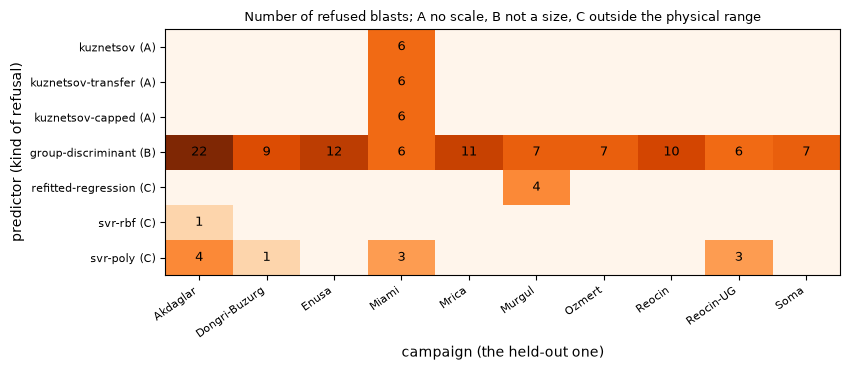

In [8]:
# Refusal matrix: predictors that refuse against the campaign they refuse on
fig, ax = plt.subplots(figsize=(8.6, 3.8))
image = ax.imshow(np.log10(matrix + 1), cmap="Oranges", aspect="auto")
for i in range(matrix.shape[0]):
    for j in range(matrix.shape[1]):
        if matrix[i, j]:
            ax.text(j, i, matrix[i, j], ha="center", va="center", fontsize=9)
ax.set_xticks(range(len(sites)), sites, rotation=35, ha="right", fontsize=8)
ax.set_yticks(range(len(refusing)), [f"{name} ({kind_of[name]})" for name in refusing], fontsize=8)
ax.set_xlabel("campaign (the held-out one)")
ax.set_ylabel("predictor (kind of refusal)")
ax.set_title("Number of refused blasts; A no scale, B not a size, C outside the physical range", fontsize=9)
fig.tight_layout()
plt.show()

**What the figure shows.** Seven predictors refuse somewhere, 131 times out of the 679 answers they could have given. Cause A is one column: Miami publishes no hole diameter, and all three classical variants refuse its six blasts, nothing else. Cause B is one row: the group discriminant refuses all 97 blasts, in every campaign, because it returns a group and not a size. Cause C is scattered: the refitted regression refuses four Murgul blasts, the radial support vector regressor one Akdaglar blast (-0.003096 m) and the polynomial one eleven blasts in four campaigns. **What it does not show:** how bad the refused numbers were, which the next step measures. **What follows:** a predictor's score can only be read together with its row of this matrix.

### Step 4: the numbers the guard refused

A refusal of kind C carries the value the model returned in its reason text. The cell recovers those values, prints the engine's plausible range, and the figure puts them on a symmetric logarithmic axis beside the accepted predictions of the same predictor and the plausible band.

In [9]:
# The numbers the guard refused: the value the model returned, from the reason text
low, high = bf.models.PLAUSIBLE_X50_M
returned = {}
for name in refusing:
    if kind_of[name] == "C":
        reasons = [p.abstain_reason for p in predictions[name] if p.abstained]
        returned[name] = [float(reason.split("returned ")[1].split(" m")[0]) for reason in reasons]
print("plausible range of a mean fragment size (m):", low, "to", high)
rows = [(n, len(v), f"{min(v):.4g}", f"{max(v):.4g}") for n, v in returned.items()]
Table(["predictor", "refused", "smallest returned (m)", "largest returned (m)"], rows)

plausible range of a mean fragment size (m): 0.001 to 3.0


| predictor | refused | smallest returned (m) | largest returned (m) |
|---|---|---|---|
| refitted-regression | 4 | 6.065 | 10.48 |
| svr-rbf | 1 | -0.003096 | -0.003096 |
| svr-poly | 11 | -0.313 | 18.9 |

The next cell places the refused values on a symmetric logarithmic axis, which keeps both the small negative numbers and the values near 10 m readable, next to the accepted predictions of the same predictor and the green plausible band. Look at how far outside the band the refused values lie.

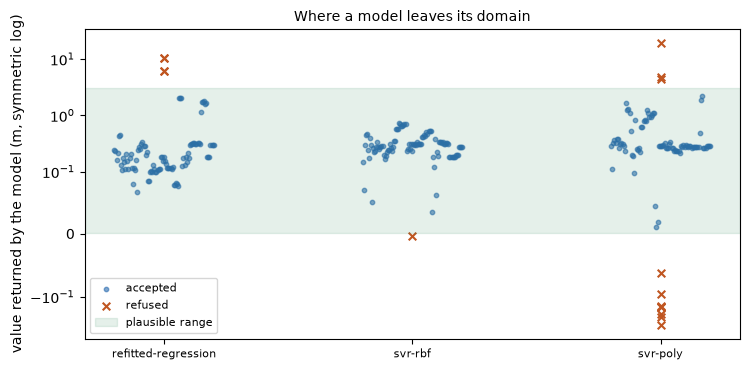

In [10]:
# Returned values against the plausible band, with the accepted predictions of the same predictor
fig, ax = plt.subplots(figsize=(7.6, 3.8))
for k, (name, values) in enumerate(returned.items()):
    accepted = [p.x50_m for p in predictions[name] if not p.abstained]
    ax.scatter(np.full(len(accepted), k) + np.linspace(-0.2, 0.2, len(accepted)), accepted, s=10, color="#2b6cb0",
        alpha=0.6,
               label="accepted" if k == 0 else None)
    ax.scatter(np.full(len(values), k), values, s=30, marker="x", color="#c05621",
        label="refused" if k == 0 else None)
ax.axhspan(low, high, color="#2f855a", alpha=0.12, label="plausible range")
ax.set_yscale("symlog", linthresh=0.1)
ax.set_xticks(range(len(returned)), list(returned), fontsize=8)
ax.set_ylabel("value returned by the model (m, symmetric log)")
ax.set_title("Where a model leaves its domain", fontsize=10)
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

**What the figure shows.** Each refused value (orange cross) lies outside the green band, and the accepted predictions (blue) sit inside it, mostly between 0.1 m and 1 m. The refitted regression returned fragment sizes of 6.065 m and 10.48 m at Murgul; the polynomial support vector regressor returned values as large as 18.9 m and as small as -0.313 m, a negative fragment size. **What it does not show:** that every accepted value is right: the band only catches the impossible, not the wrong. **What follows:** these predictors left the physical range on a campaign unlike their training rows, and the guard turned arithmetic into a counted refusal. Scoring those numbers would have made the pooled r2 of the predictor depend on a handful of absurd values.

### Step 5: the fair comparison on common rows

The cell keeps the rows that all twelve size-predicting predictors answered (the discriminant never answers and the oracle is a control, not a competitor), reports which rows had to go, and scores each predictor on those rows alone. The figure sets that score beside the one on the predictor's own rows, clipped at -2 so that the worst predictors do not flatten the rest.

In [11]:
# Rows every size-predicting predictor answered, and each predictor scored on them alone
sizers = [name for name in predictions if name not in ("group-discriminant", "oracle")]
common = [i for i in range(len(tested)) if all(not predictions[name][i].abstained for name in sizers)]
print(len(common), "common rows from", len({tested[i].site for i in common}), "campaigns")
dropped = [tested[i].site for i in range(len(tested)) if i not in common]
print("rows left out of the common set, by campaign:", {s: dropped.count(s) for s in sorted(set(dropped))})
on_common = {}
for name in sizers:
    on_common[name] = bf.score([tested[i] for i in common], [predictions[name][i] for i in common], method=name)
rows = [(n, scores[n].n_scored, f"{scores[n].r2_identity:.3f}", f"{on_common[n].r2_identity:.3f}") for n in sizers]
Table(["predictor", "own rows", "r2 own rows", "r2 common rows"], rows)

79 common rows from 9 campaigns
rows left out of the common set, by campaign: {'Akdaglar': 4, 'Dongri-Buzurg': 1, 'Miami': 6, 'Murgul': 4, 'Reocin-UG': 3}


| predictor | own rows | r2 own rows | r2 common rows |
|---|---|---|---|
| null | 97 | -0.216 | -0.229 |
| kuznetsov | 91 | 0.311 | 0.318 |
| kuznetsov-transfer | 91 | 0.298 | 0.293 |
| kuznetsov-capped | 91 | 0.352 | 0.364 |
| published-regression | 97 | 0.802 | 0.766 |
| refitted-regression | 93 | -4.075 | -3.715 |
| published-neural-net | 97 | -0.626 | -0.491 |
| svr-rbf | 96 | -0.387 | -0.329 |
| svr-poly | 86 | -4.546 | -4.837 |
| random-forest | 97 | -0.231 | -0.167 |
| xgboost | 97 | -0.034 | 0.212 |
| stacking | 97 | -0.035 | 0.215 |

The next cell sets each predictor's pooled score on its own rows beside its score on the common rows, in descending order of the second, and clips both at -2 so that the worst predictors do not flatten the scale. Look at which bars move between the two and which do not.

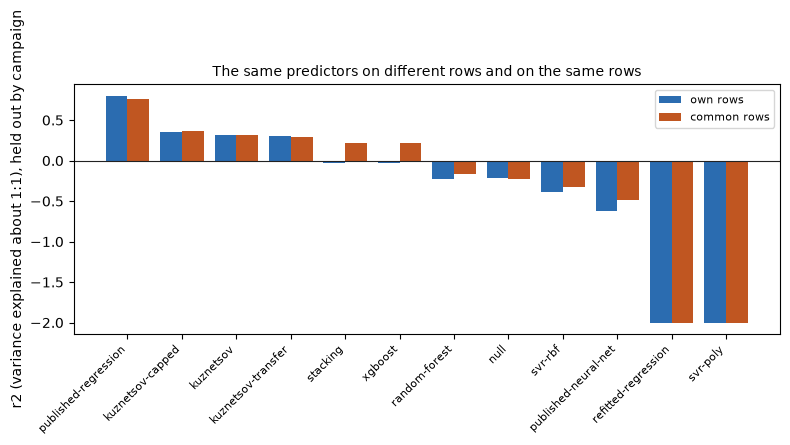

In [12]:
# Pooled score on each predictor's own rows against the score on the common rows, clipped at -2
ranked = sorted(sizers, key=lambda name: -on_common[name].r2_identity)
x = np.arange(len(ranked))
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(x - 0.2, [max(scores[n].r2_identity, -2) for n in ranked], 0.4, color="#2b6cb0", label="own rows")
ax.bar(x + 0.2, [max(on_common[n].r2_identity, -2) for n in ranked], 0.4, color="#c05621", label="common rows")
ax.axhline(0, color="#222", lw=0.8)
ax.set_xticks(x, ranked, rotation=45, ha="right", fontsize=8)
ax.set_ylabel("r2 (variance explained about 1:1), held out by campaign")
ax.set_title("The same predictors on different rows and on the same rows", fontsize=10)
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

**What the figure shows.** On the 79 common rows the ranking changes in size but little in order. Gradient boosting and stacking move from -0.034 and -0.035 to +0.212 and +0.215, because the rows that leave the set include all six Miami blasts and the blasts where the weakest predictors refused (Akdaglar 4, Murgul 4, Reocin-UG 3, Dongri-Buzurg 1). The classical variants hardly move (0.311 to 0.318, 0.298 to 0.293, 0.352 to 0.364). Four predictors stay below the null on the common rows: the refitted regression (-3.715), the polynomial support vector regressor (-4.837), the network (-0.491) and the radial support vector regressor (-0.329). **What it does not show:** a verdict. The rows depend on who refused, so a predictor that refuses its hard rows looks better on the rows it keeps.

### Reproduction check: the pooled scores of the bake

This run is the one the offline bake performs, so its pooled scores must equal the ones written in `benchmark.json`. The cell takes the largest difference over every predictor with a score.

In [13]:
# The one reproduction check: every pooled score equals the one the bake wrote
benchmark = json.loads((DERIVED / "benchmark.json").read_text(encoding="utf-8"))
loso = benchmark["protocols"]["leave-one-site-out"]["arms"]
rescored = {n: bf.score(tested, predictions[n], method=n).r2_identity for n in predictions}
gaps = [abs(r2 - loso[n]["r2_identity"]) for n, r2 in rescored.items() if r2 is not None]
print("largest difference to the baked pooled scores over",
      len(gaps), "predictors:", f"{max(gaps):.1e}")

largest difference to the baked pooled scores over 13 predictors: 0.0e+00


## Results

**Answer:** each predictor refuses for one of three reasons that the engine states, and on the rows they all answer only the forest, boosting and stacking beat the null among the learned predictors. A needed input is missing (A: Miami has no hole diameter, so the three classical variants refuse its 6 blasts), the predictor is not a size predictor (B: the group discriminant refuses all 97), or its number leaves the physical range of 0.001 m to 3.0 m (C: the refitted regression 4 blasts, the radial support vector regressor 1, the polynomial one 11). Pooled over each predictor's own rows the classical variants score 0.311, 0.298 and 0.352, boosting -0.034 and the null -0.216; on the 79 common rows boosting and stacking reach 0.212 and 0.215, the forest -0.167, the classical variants stay at 0.318, 0.293 and 0.364, and the network, both support vector regressors and the refitted regression stay below the null (-0.229).

The scores of the published regression (0.802) and of the classical variants are not out-of-sample numbers in the same sense as the learned ones: the first was fitted on these rows and the second takes its rock factor from the source's own published predictions. The honest reading of the ranking is therefore short: no learned predictor beats the classical equation held out by campaign, and the best learned ones, boosting and stacking, score near zero on all rows.

**What this does not show.** The common-rows score is a diagnostic, not a ranking, because the common rows are the ones nobody refused. Nor does the notebook decide which criterion a predictor must meet; that is the pre-declared criterion of topic 04. And the refusal counts describe this corpus, ten campaigns, one of which publishes no geometry.

## Summary

- All fourteen predictors run through the ten folds, each rebuilt fresh in every fold, and each one's pooled score is reported with its refusals.
- A refusal has one of three causes: an input that cannot be known (Miami), a predictor that is not a size predictor (the discriminant), or an output outside 0.001 m to 3.0 m (refitted regression, both support vector regressors).
- On the 79 rows every size predictor answered, boosting and stacking reach 0.212 and 0.215 and four predictors stay below the null.
- Next: notebook 03 reproduces the published neural network and asks what its published hold-out score is worth (level 3).

## References

- Kulatilake, Hudaverdi and Wu 2012, https://doi.org/10.1007/s10706-012-9496-3 (the back-propagation network and its hold-out)
- Sui, Zhou, Zhao, Yang and Zou 2025, https://doi.org/10.3390/app15031254 (support vector polynomial, forest, boosting, stacking)
- Hudaverdi, Kulatilake and Kuzu 2010, https://doi.org/10.1002/nag.957 (the corpus and the published regression)
- `blastfrag` 0.4.0, the engine, on PyPI: https://pypi.org/project/blastfrag/